# Day 4: Project, Binary Classifier on Tabular Data (Notebook 3)

**Dataset:** Breast Cancer (scikit-learn, 569 samples, 30 features)
**Model:** PyTorch MLP `30 -> 32 -> 16 -> 1`, `BCEWithLogitsLoss`
**Goal:** train, track train/val curves, evaluate on test set, aur Week 3 models se honestly compare karna.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
import os
IMG_DIR = "../images" if os.path.basename(os.getcwd()) == "notebooks" else "images"
os.makedirs(IMG_DIR, exist_ok=True)

## 1. Data

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

print("X shape:", X.shape)
print("classes:", {str(n): int(c) for n, c in zip(data.target_names, np.bincount(y))})   # 0 = malignant, 1 = benign
print("pehle 5 features:", [str(f) for f in data.feature_names[:5]])

X shape: (569, 30)
classes: {'malignant': 212, 'benign': 357}
pehle 5 features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


## 2. Stratified train / validation / test split (70 / 15 / 15)

- **Stratified:** har split me class ratio same rahe.
- **Scaling:** `StandardScaler` sirf **train par fit** hota hai. Val aur test par sirf `transform`. Warna data leakage hoti hai.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)          # sirf train par fit
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("train:", X_train_s.shape, " val:", X_val_s.shape, " test:", X_test_s.shape)
print("malignant ratio -> train/val/test:",
      round((y_train == 0).mean(), 3), round((y_val == 0).mean(), 3), round((y_test == 0).mean(), 3))

train: (397, 30)  val: (86, 30)  test: (86, 30)
malignant ratio -> train/val/test: 0.373 0.372 0.372


In [4]:
def to_tensors(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32).reshape(-1, 1))

X_train_t, y_train_t = to_tensors(X_train_s, y_train)
X_val_t,   y_val_t   = to_tensors(X_val_s,   y_val)
X_test_t,  y_test_t  = to_tensors(X_test_s,  y_test)

train_ds = TensorDataset(X_train_t, y_train_t)

## 3. Model

Output layer par sigmoid nahi lagate. Model logits deta hai, aur `BCEWithLogitsLoss` sigmoid + BCE ek saath karta hai.
Prediction ke waqt `sigmoid(logits) > 0.5`.

In [5]:
class BinaryMLP(nn.Module):
    def __init__(self, n_in=30, h1=32, h2=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, h1), nn.ReLU(),
            nn.Linear(h1, h2),   nn.ReLU(),
            nn.Linear(h2, 1),
        )

    def forward(self, x):
        return self.net(x)

print(BinaryMLP())

BinaryMLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 4. Training with train/val tracking

In [6]:
def evaluate(model, X, y, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) > 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(seed=SEED, epochs=100, lr=1e-3, batch_size=32):
    torch.manual_seed(seed)
    model = BinaryMLP()
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        tl, ta = evaluate(model, X_train_t, y_train_t, criterion)
        vl, va = evaluate(model, X_val_t,   y_val_t,   criterion)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl);   hist["val_acc"].append(va)
    return model, hist

model, hist = train_model()
print(f"final train loss {hist['train_loss'][-1]:.4f} | val loss {hist['val_loss'][-1]:.4f}")
print(f"final train acc  {hist['train_acc'][-1]:.3f} | val acc  {hist['val_acc'][-1]:.3f}")

final train loss 0.0039 | val loss 0.0072
final train acc  1.000 | val acc  1.000


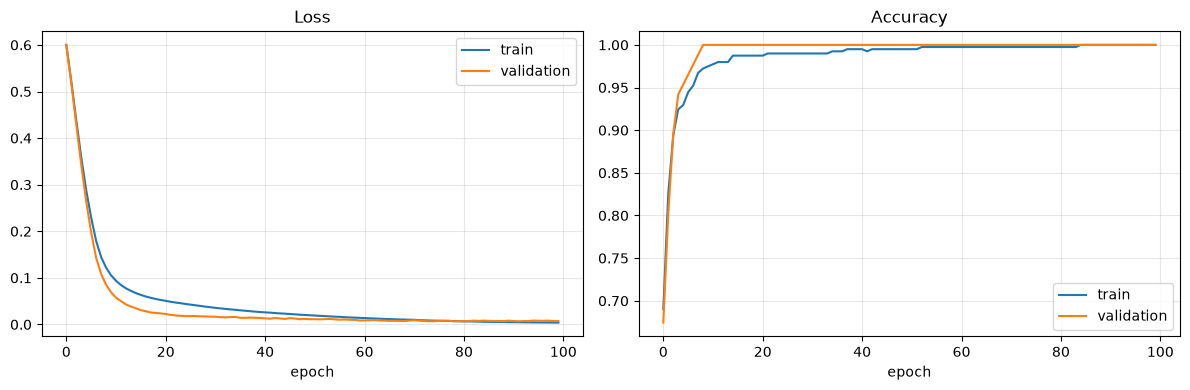

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist["train_loss"], label="train")
axes[0].plot(hist["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(hist["train_acc"], label="train")
axes[1].plot(hist["val_acc"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{IMG_DIR}/breast_cancer_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Test set evaluation

Test set ko **sirf ek baar, aakhir me** use karte hain. Is par hyperparameters tune nahi karte.

Note: scikit-learn me `0 = malignant`, `1 = benign`. Cancer detection me asli risk malignant ko miss karna hai, isliye `classification_report` me dono classes ka recall dekho.

Accuracy : 0.942
Precision: 0.980
Recall   : 0.926
F1       : 0.952

              precision    recall  f1-score   support

   malignant       0.89      0.97      0.93        32
      benign       0.98      0.93      0.95        54

    accuracy                           0.94        86
   macro avg       0.93      0.95      0.94        86
weighted avg       0.95      0.94      0.94        86



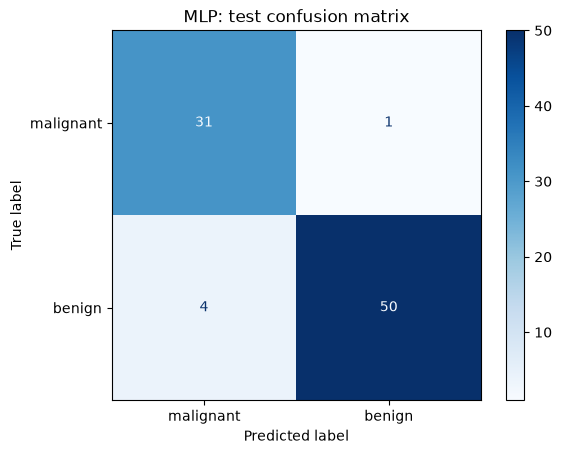

In [8]:
model.eval()
with torch.no_grad():
    probs = torch.sigmoid(model(X_test_t)).numpy().ravel()
y_pred = (probs > 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1       : {f1_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("MLP: test confusion matrix")
plt.savefig(f"{IMG_DIR}/breast_cancer_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Week 3 models se comparison (same split, same scaled data)

Ye baseline models usi train/test split par train hote hain, taake comparison fair ho.
Apne Week 3 notebook ke numbers alag split ki wajah se thore different ho sakte hain.

In [9]:
def metrics_row(name, y_true, y_hat):
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat),
        "Recall":    recall_score(y_true, y_hat),
        "F1":        f1_score(y_true, y_hat),
    }

rows = [metrics_row("MLP (PyTorch)", y_test, y_pred)]

baselines = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF)":           SVC(kernel="rbf", C=1.0),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED),
}
for name, clf in baselines.items():
    clf.fit(X_train_s, y_train)
    rows.append(metrics_row(name, y_test, clf.predict(X_test_s)))

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Accuracy,Precision,Recall,F1
Model,,,,
MLP (PyTorch),0.942,0.980,0.926,0.952
Logistic Regression,0.965,0.981,0.963,0.972
SVM (RBF),0.965,0.981,0.963,0.972
Random Forest,0.919,0.961,0.907,0.933


## 7. Honest check: kya MLP ne beat kiya?

Test set sirf 86 samples ka hai, yaani ek galat prediction se accuracy lagbhag 1.2% badal jati hai.
Ek hi run se conclusion nikalna theek nahi. Isliye MLP ko 5 alag seeds par train karke mean aur std dekhte hain.

In [10]:
test_accs = []
for s in range(5):
    m, _ = train_model(seed=s)
    _, acc = evaluate(m, X_test_t, y_test_t, nn.BCEWithLogitsLoss())
    test_accs.append(acc)
    print(f"seed {s}: test acc {acc:.3f}")

print(f"\nMLP test accuracy over 5 seeds: {np.mean(test_accs):.3f} +/- {np.std(test_accs):.3f}")

seed 0: test acc 0.942
seed 1: test acc 0.942
seed 2: test acc 0.942
seed 3: test acc 0.942
seed 4: test acc 0.942

MLP test accuracy over 5 seeds: 0.942 +/- 0.000


## 8. Experiments (khud karo)

1. `epochs` 20, 100, 300 karo. Val loss kab upar jane lagta hai (overfitting ke signs)?
2. `lr` 0.0001, 0.001, 0.01 karo.
3. Hidden sizes badlo (8/4 vs 64/32).
4. Scaling hata kar train karo (raw features). Kya hota hai?
5. Optional: Titanic dataset par yehi pipeline.

## 9. Notes (apne words me likho)

- Stratified split aur "scaler sirf train par fit" kyun:
- Train/val curves kya batati hain:
- Accuracy ke saath precision, recall, F1 kyun dekhte hain:
- MLP ne Week 3 models ko beat kiya ya nahi, aur kyun (small tabular data):